In [25]:
# Setting the notebook up
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%cd /Users/bensilvesterratcliffe/Documents/Coding/ai-ml-summer-2026/projects/Chess-outcome-predictor
sns.set_theme(style="whitegrid")
print("Ready!")

/Users/bensilvesterratcliffe/Documents/Coding/ai-ml-summer-2026/projects/Chess-outcome-predictor
Ready!


In [ ]:
# Load the data
file_path_lichess = "data/processed/rapid_games_A_lichess.csv"
file_path_chesscom = "data/processed/rapid_games_A.csv"

lichess_data = pd.read_csv(file_path_lichess)
chesscom_data = pd.read_csv(file_path_chesscom)

print(lichess_data.head())
print(chesscom_data.head())

   white_elo  black_elo result
0       1673       1603  white
1        400        840  black
2       1470       1480  black
3       1317       1311  white
4       1447       1424  black
   white_elo  black_elo result
0       1423       1327  white
1        168        452  black
2       1150       1163  black
3        962        955  white
4       1121       1092  black


In [27]:
# Basic checks
print(f"Number of games: {len(chesscom_data):,}")

print("\nColumns:")
print(chesscom_data.columns.tolist())

print("\nMissing values:")
print(chesscom_data.isna().sum())

print("\nData types:")
print(chesscom_data.dtypes)

Number of games: 1,000,000

Columns:
['white_elo', 'black_elo', 'result']

Missing values:
white_elo    0
black_elo    0
result       0
dtype: int64

Data types:
white_elo    int64
black_elo    int64
result         str
dtype: object


In [ ]:
# Elo summary and comparison
print("White Elo (lichess):")
display(lichess_data["white_elo"].describe())

print("White Elo (chess.com):")
display(chesscom_data["white_elo"].describe())

print("Black Elo (chess.com):")
display(chesscom_data["black_elo"].describe())

print("Black Elo (lichess):")
display(lichess_data["black_elo"].describe())

White Elo (lichess):


count    1000000.000000
mean        1459.733201
std          371.294654
min          400.000000
25%         1196.000000
50%         1485.000000
75%         1733.000000
max         3059.000000
Name: white_elo, dtype: float64

White Elo (chess.com):


count    1000000.000000
mean        1169.736297
std          456.271202
min          156.000000
25%          825.000000
50%         1170.000000
75%         1507.000000
max         3059.000000
Name: white_elo, dtype: float64

Black Elo (chess.com):


count    1000000.000000
mean        1169.467252
std          456.749585
min          156.000000
25%          825.000000
50%         1167.000000
75%         1507.000000
max         3061.000000
Name: black_elo, dtype: float64

Black Elo (lichess):


count    1000000.000000
mean        1459.466252
std          371.685019
min          400.000000
25%         1196.000000
50%         1483.000000
75%         1733.000000
max         3061.000000
Name: black_elo, dtype: float64

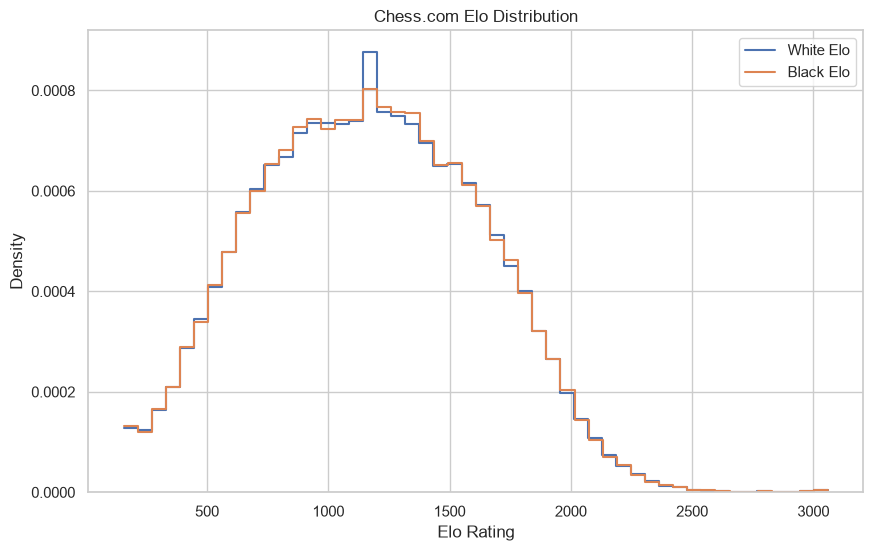

In [29]:
# Elo distribution
data = chesscom_data
plt.figure(figsize=(10, 6))

sns.histplot(
    data=data,
    x="white_elo",
    bins=50,
    stat="density",
    element="step",
    fill=False,
    label="White Elo",
)

sns.histplot(
    data=data,
    x="black_elo",
    bins=50,
    stat="density",
    element="step",
    fill=False,
    label="Black Elo",
)

plt.title("Chess.com Elo Distribution")
plt.xlabel("Elo Rating")
plt.ylabel("Density")
plt.legend()
plt.show()

In [40]:
# Game result proportions
result_order = ["white", "draw", "black"]

result_labels = ["White Win", "Draw", "Black Win"]

result_proportions = (
    data["result"]
    .value_counts(normalize=True)
    .reindex(result_order, fill_value=0)
)

result_table = pd.DataFrame({
    "Result": result_labels,
    "Proportion": result_proportions.values,
})

display(result_table)

,Result,Proportion
0,White Win,0.494695
1,Draw,0.047112
2,Black Win,0.458193


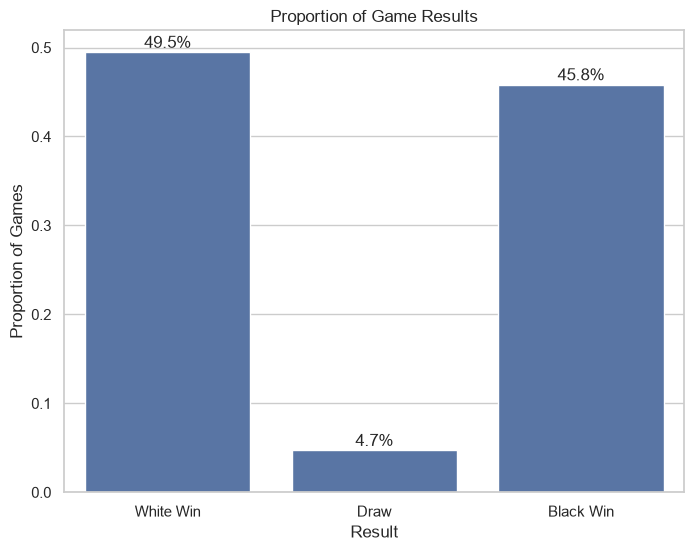

In [ ]:
plt.figure(figsize=(8, 6))

ax = sns.barplot(
    x=result_labels,
    y=result_proportions.values,
)

plt.title("Proportion of Game Results")
plt.xlabel("Result")
plt.ylabel("Proportion of Games")

# Add percentages above the bars
for i, proportion in enumerate(result_proportions.values):
    ax.text(
        i,
        proportion + 0.005,
        f"{proportion:.1%}",
        ha="center",
    )

plt.show()

In [ ]:
# Find the rating differences
data["rating_difference"] = (
    data["white_elo"] - data["black_elo"]
)

data["rating_difference"].describe()

count    1000000.000000
mean           0.269045
std          169.766816
min        -2586.000000
25%          -47.000000
50%            0.000000
75%           47.000000
max         2594.000000
Name: rating_difference, dtype: float64

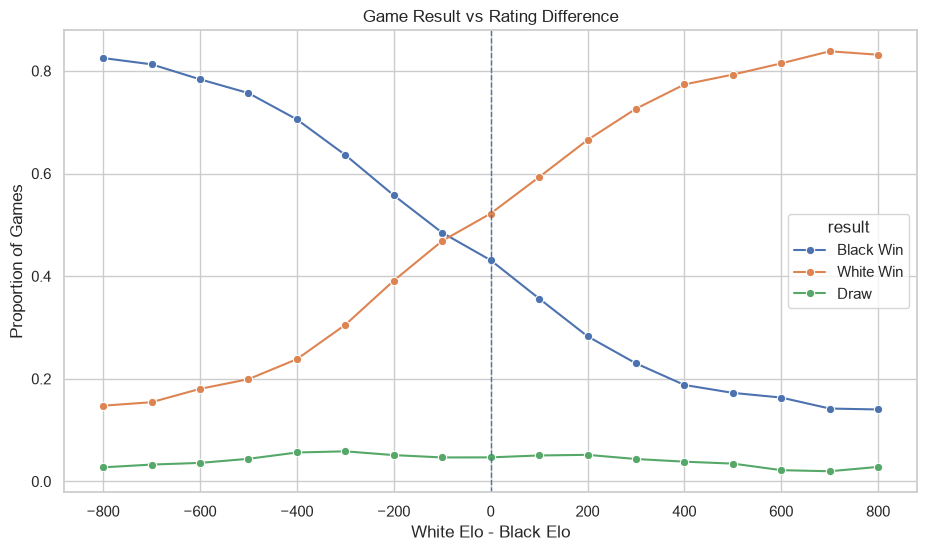

In [42]:
# Plot the rating differences
data["rating_difference_bin"] = (data["rating_difference"] // 100) * 100

result_by_difference = (
    data.groupby("rating_difference_bin")["result"]
    .value_counts(normalize=True)
    .rename("proportion")
    .reset_index()
)

result_by_difference["result"] = (
    result_by_difference["result"].replace({
        "white": "White Win",
        "draw": "Draw",
        "black": "Black Win",
    })
)

# Focus the visualisation on -800 to +800 Elo.
# Extreme differences are likely to contain relatively few games.
plot_data = result_by_difference[result_by_difference["rating_difference_bin"].between(-800, 800)]

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=plot_data,
    x="rating_difference_bin",
    y="proportion",
    hue="result",
    marker="o",
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.title("Game Result vs Rating Difference")
plt.xlabel("White Elo - Black Elo")
plt.ylabel("Proportion of Games")

plt.show()

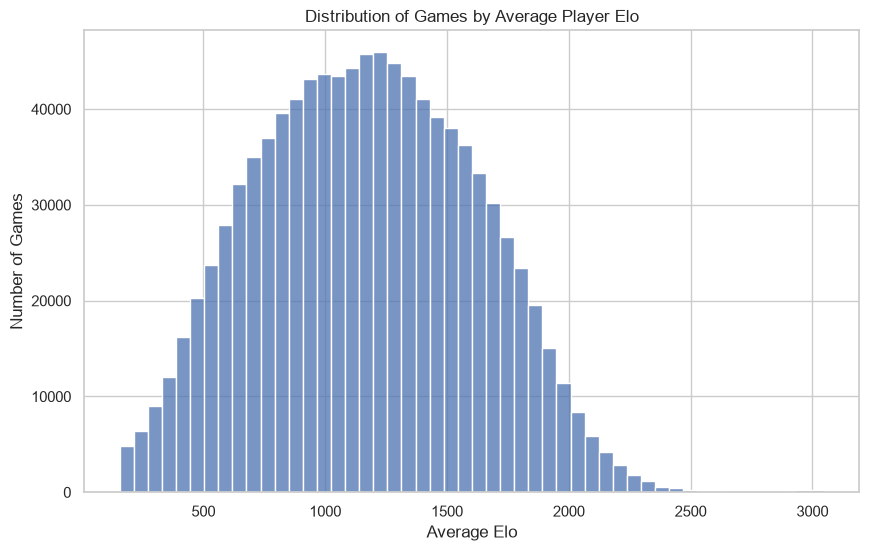

0.01     262.0
0.05     450.0
0.25     830.0
0.50    1166.0
0.75    1501.5
0.95    1901.5
0.99    2150.0
Name: average_elo, dtype: float64

In [ ]:
# Investigation into the distribution of games by average ELO
data["average_elo"] = (
    data["white_elo"] + data["black_elo"]
) / 2

plt.figure(figsize=(10, 6))

sns.histplot(
    data=data,
    x="average_elo",
    bins=50,
)

plt.title("Distribution of Games by Average Player Elo")
plt.xlabel("Average Elo")
plt.ylabel("Number of Games")

plt.show()

data["average_elo"].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

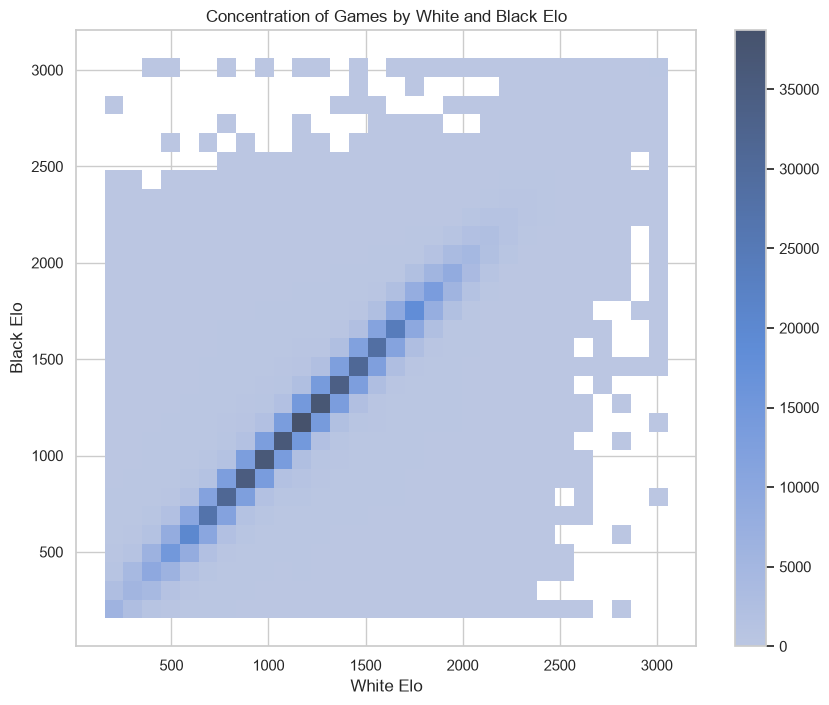

In [ ]:
# Investigation into the distribution of games by each side's ELO
plt.figure(figsize=(10, 8))

sns.histplot(
    data=data,
    x="white_elo",
    y="black_elo",
    bins=30,
    cbar=True,
)

plt.title("Concentration of Games by White and Black Elo")
plt.xlabel("White Elo")
plt.ylabel("Black Elo")

plt.show()